## Read embeddings

In [107]:
import pandas as pd
MODELS_DESCRIPTIONS = {
    "mix_of_alleles_balanced":
    {
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "path": "experiment_results/alleles_with_groups_balanced/",
        "states": 25,
        "params_string": "5-min_iters",
        "target_lengths": [9, 10]
    }

}

In [108]:
selected_model = MODELS_DESCRIPTIONS["mix_of_alleles_balanced"]

selected_alleles = selected_model['alleles']
states = selected_model['states']
TARGET_LENGTHS = selected_model['target_lengths']
selected_combination = "+".join(selected_alleles).replace('-', '_').replace('*', '_').replace(':', '_')
selected_model_split = 0 # should match to data split (if original train/test used) in order to have true test case
selected_model_run = 0
target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])

In [109]:
mixed_model_bw =f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'
mixed_model_bwv = f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}_plus_viterbi'
mixed_model_v = f'{selected_model_run}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'

name_to_model_root = dict()
name_to_model_root[mixed_model_bw] = selected_model['path']
name_to_model_root[mixed_model_bwv] = selected_model['path']
name_to_model_root[mixed_model_v] = selected_model['path']

In [110]:
def load_embeddings(model):
    print(f"model {model}")
    TARGET_PATH_TO_FILES = name_to_model_root[model] + model
    # Train 
    train_df =  pd.read_csv("{}/train_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)
    # Test 
    test_df =  pd.read_csv("{}/test_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)

    # paths_df['path'] = paths_df['path'].apply(pd.eval)
    # paths_df['path'] = paths_df['path'].astype(list)
    return  train_df, test_df


In [111]:
%%time
per_model_type_train_embeddings = dict()
per_model_type_test_embeddings = dict()
# BW
train_df, test_df = load_embeddings(mixed_model_bw)
per_model_type_train_embeddings['bw'] = train_df
per_model_type_test_embeddings['bw'] = test_df
# BWV
train_df, test_df = load_embeddings(mixed_model_bwv)
per_model_type_train_embeddings['bwv'] = train_df
per_model_type_test_embeddings['bwv'] = test_df
# V
train_df, test_df = load_embeddings(mixed_model_v)
per_model_type_train_embeddings['v'] = train_df
per_model_type_test_embeddings['v'] = test_df

model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
Wall time: 29.4 s


# Hierarchical clustering of paths in the space of peptides

In [112]:
df = per_model_type_train_embeddings["v"].copy()
label_to_index = {label: i for i, label in enumerate(selected_alleles)}
df['label'] = df['allele'].map(label_to_index)
labels = selected_alleles

In [113]:
X = df.drop(columns=['allele', 'label', 'peptide']).values
TOP = 2000
X = X.T[:TOP]
print(f"Shape of data {X.shape}")

Shape of data (2000, 19873)


In [114]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

[]

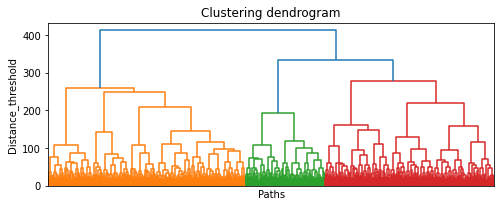

In [115]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 3))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'), ax=ax)
ax.set_xlabel('Paths')
ax.set_ylabel('Distance_threshold')
ax.set_title(f"Clustering dendrogram")
ax.set_xticks([])

In [116]:
model = AgglomerativeClustering(
    n_clusters=None, linkage="ward", affinity='euclidean', distance_threshold=300
)
model.fit(X)

AgglomerativeClustering(distance_threshold=300, n_clusters=None)

In [117]:
unique_labels_counts = pd.Series(model.labels_).value_counts().sort_values(ascending=False)
path_to_label = {i:model.labels_[i] for i in range(X.shape[0])}
unique_labels_counts

1    887
0    758
2    355
dtype: int64

In [118]:
peptide_df = pd.DataFrame({"peptide": df.index.values, "allele": df['allele']})

In [119]:
df[[str(path) for path, cur_label in path_to_label.items() if cur_label == label]]

,4,10,14,16,18,19,21,31,37,38,...,1940,1941,1946,1948,1952,1954,1962,1966,1968,1991
STSGTVINK,-1.050147,-0.970940,-1.068645,-1.056322,-0.933689,-1.058364,-1.095559,-1.191853,-1.186744,-0.840863,...,-1.093458,-1.089447,-1.118092,-0.822599,-1.108834,-1.029866,-0.938282,-1.111591,-0.917742,-0.816084
KDFKCFNLI,-0.803121,-1.107914,-0.892930,-1.043849,-1.004703,-1.006785,-1.005733,-1.009999,-0.802279,-1.227395,...,-0.866985,-0.880131,-0.996263,-1.328711,-1.128922,-0.972894,-0.894240,-1.116725,-0.992067,-1.116726
VLYAASTLYK,-0.968827,-0.831823,-0.977167,-0.583866,-0.728569,-0.713035,-0.831268,-0.835533,-0.829207,-0.955590,...,-0.860980,-0.837477,-0.730705,-0.948658,-0.827348,-0.950178,-0.805926,-0.713206,-1.064959,-1.103625
ELDGLFRRY,-1.185172,-1.105256,-1.193512,-1.057528,-1.197112,-1.056944,-1.104700,-1.190434,-1.045552,-1.224736,...,-1.203430,-1.192377,-1.122899,-1.241249,-0.976118,-1.025627,-0.973051,-1.101113,-1.148717,-1.315683
ALKNPPINTK,-1.193853,-0.801549,-1.202193,-0.939976,-1.197513,-1.057346,-1.056293,-1.060559,-1.113662,-0.798618,...,-0.964254,-0.996833,-0.983877,-0.952323,-1.050894,-1.108018,-0.995476,-0.839679,-1.036110,-1.027900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LLSYPLVLK,-0.948303,-0.589070,-0.956643,-0.554846,-0.951963,-0.811796,-0.718716,-0.815010,-1.084901,-0.723295,...,-0.981456,-0.977445,-0.881458,-1.064457,-0.866351,-0.924108,-1.180905,-0.874416,-0.927176,-0.963358
PIIVAGFSGK,-1.214484,-1.219729,-1.093486,-0.973646,-0.965656,-1.220226,-1.219174,-1.223439,-1.163361,-1.216798,...,-0.876546,-1.042293,-0.877484,-1.077877,-1.282736,-1.313450,-1.267750,-1.004873,-1.094288,-1.093246
RLADVLIKR,-0.939150,-0.790736,-0.947490,-0.869101,-0.811598,-0.802643,-0.801590,-0.805856,-0.938308,-0.924961,...,-0.817453,-0.808021,-0.956946,-1.328902,-0.811786,-0.671210,-1.056131,-0.949904,-0.736489,-1.093394
ILAEYIRHR,-1.122375,-1.115285,-1.130715,-1.055093,-1.019379,-1.010424,-0.984816,-0.989081,-1.121533,-0.986577,...,-1.142001,-1.154359,-1.142939,-1.170759,-0.941682,-0.816786,-1.182710,-0.872965,-0.679095,-1.134612


In [120]:
for label in unique_labels_counts.index:
    # peptide_df[f'path_gr_{label}'] = np.exp(df[ [path for path, cur_label in path_to_label.items() if cur_label == label]]).mean(axis=1).values
    peptide_df[f'path_gr_{label}'] = df[[str(path) for path, cur_label in path_to_label.items() if cur_label == label]].max(axis=1).values


In [121]:
peptide_df['max_label'] = peptide_df[[f'path_gr_{label}' for label in path_to_label.values()]].idxmax(axis=1)
peptide_df['len'] = peptide_df['peptide'].str.len()
peptide_df

,peptide,allele,path_gr_1,path_gr_0,path_gr_2,max_label,len
STSGTVINK,STSGTVINK,HLA-A*03:01,-0.688613,-0.688984,-0.693907,path_gr_1,9
KDFKCFNLI,KDFKCFNLI,HLA-A*01:01,-0.741042,-0.621743,-0.660071,path_gr_0,9
VLYAASTLYK,VLYAASTLYK,HLA-A*03:01,-0.522367,-0.405043,-0.319632,path_gr_2,10
ELDGLFRRY,ELDGLFRRY,HLA-A*01:01,-0.722569,-0.436587,-0.602104,path_gr_0,9
ALKNPPINTK,ALKNPPINTK,HLA-A*03:01,-0.670335,-0.567326,-0.555004,path_gr_2,10
...,...,...,...,...,...,...,...
LLSYPLVLK,LLSYPLVLK,HLA-A*03:01,-0.411346,-0.521781,-0.434265,path_gr_1,9
PIIVAGFSGK,PIIVAGFSGK,HLA-A*03:01,-0.484038,-0.653773,-0.661505,path_gr_1,10
RLADVLIKR,RLADVLIKR,HLA-A*03:01,-0.654824,-0.589966,-0.500143,path_gr_2,9
ILAEYIRHR,ILAEYIRHR,HLA-A*03:01,-0.634415,-0.646879,-0.679095,path_gr_1,9


In [122]:
peptide_df.max_label.value_counts()

path_gr_1    8364
path_gr_0    7960
path_gr_2    3549
Name: max_label, dtype: int64

In [123]:
peptide_df.groupby(['max_label','allele', 'len'])['peptide'].count()

max_label  allele       len
path_gr_0  HLA-A*01:01  9      2116
                        10      993
           HLA-A*02:01  9      1687
                        10      763
           HLA-A*03:01  9      1592
                        10      809
path_gr_1  HLA-A*01:01  9      1682
                        10      737
           HLA-A*02:01  9      1958
                        10      995
           HLA-A*03:01  9      2053
                        10      939
path_gr_2  HLA-A*01:01  9       668
                        10      393
           HLA-A*02:01  9       899
                        10      364
           HLA-A*03:01  9       843
                        10      382
Name: peptide, dtype: int64

0
1
2
0
1
2


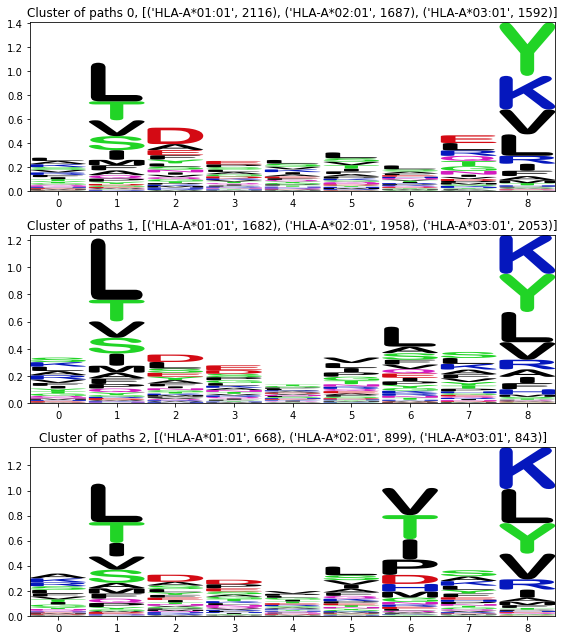

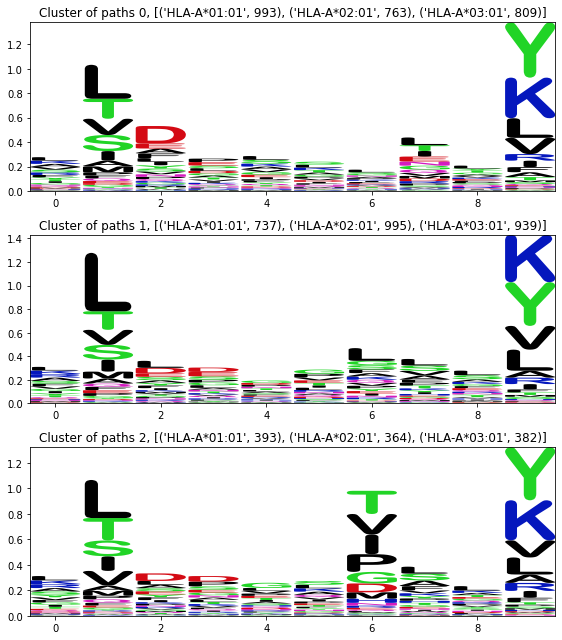

In [124]:
import matplotlib.pyplot as plt
import logomaker
for target_length in TARGET_LENGTHS:
    fig, axes = plt.subplots(nrows=len(unique_labels_counts), figsize=(8, 3*len(unique_labels_counts)))
    for i, label in enumerate(sorted(unique_labels_counts.index)):
        target_label = f'path_gr_{label}'
        print(i)
        # filtered_df =  peptide_df.sort_values(by=f'path_gr_{label}', ascending=False)[:400]
        filtered_df =  peptide_df[peptide_df['max_label'] == target_label]
        filtered_df = filtered_df[filtered_df['len'] == target_length]
        # filtered_df =  filtered_df.sort_values(by=target_label, ascending=False)[:1000]
        counts = filtered_df['allele'].value_counts()


        matrix = logomaker.alignment_to_matrix(filtered_df['peptide'].values)
        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
        ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=axes[i])
        # counts_list = [(key, value) for key, value in sorted(counts.items())]
        counts = [(key, value) for key, value in sorted(counts.items())]
        ww_logo.ax.set_title(f"Cluster of paths {label}, {counts}")
    plt.tight_layout()


## Make PCA and save to file 

In [125]:
import sklearn
import seaborn as sns
from sklearn.decomposition import PCA
from collections import defaultdict

def get_pca(df_concat, n_components=2, target_cols=["allele","dataset", "label", "peptide"],  whiten=True):
    X = df_concat.drop(columns=target_cols, errors='ignore').values
    pca = PCA(n_components=n_components, whiten=whiten)
    print(f"Shape {X.shape}")
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

def get_pca_embedding(pca, data, target_cols=["allele","dataset", "label", "peptide"]):
    X = data.drop(columns=target_cols, errors='ignore').values
    print(f"Shape of X {X.shape}")
    pca_result = pca.transform(X)
    df = pd.DataFrame(pca_result, index=data.index)
    return df



def collect_embeddings_with_pca_or_without(train_data, test_data, pca):
    columns_to_drop = ["dataset", "allele", "label", "peptide"]
    if pca:
        train_embedding = train_data.drop(columns=columns_to_drop, errors='ignore')
        test_embedding = test_data.drop(columns=columns_to_drop, errors='ignore')
        train_embedding = get_pca_embedding(pca, train_embedding)
        test_embedding = get_pca_embedding(pca, test_embedding)
    else:
        train_embedding = train_data.drop(columns=columns_to_drop, errors='ignore')
        test_embedding = test_data.drop(columns=columns_to_drop, errors='ignore')
        
    if "allele" in train_data.columns:
        alleles_train = train_data['allele'].values
        alleles_test = test_data['allele'].values


    train_df = pd.DataFrame(train_embedding, index=train_data.index)
    train_df['dataset'] = 'Train'
    train_df['allele'] = alleles_train
    test_df = pd.DataFrame(test_embedding, index=test_data.index)
    test_df['dataset'] = 'Test'
    test_df['allele'] = alleles_test

    total_embedding = pd.concat([train_df, test_df])
    return total_embedding


def get_embedding_for_selected_models_using_pca(pca_bw, pca_bwv, pca_v):
    per_model_embedding_result= dict()
    for model_key in ['bw', 'bwv', 'v']:
        if model_key == 'bw':
            model_name = 'bw'
            pca = pca_bw
        elif model_key == 'bwv':
            model_name = 'bwv'
            pca = pca_bwv
        else:
            model_name = 'v'
            pca = pca_v

        train_repr = per_model_type_train_embeddings[model_name].copy()
        test_repr = per_model_type_test_embeddings[model_name].copy()
        total_embedding_db = collect_embeddings_with_pca_or_without(train_repr, test_repr, pca)
        total_embedding_db['dataset'] = total_embedding_db['dataset'] + '_db'

        total_embedding = pd.concat([total_embedding_db])
        per_model_embedding_result[model_key] = total_embedding
    return per_model_embedding_result


In [126]:
test_embedding.values

array([['TSSSHTLTY', -0.3325227913569009, -0.3357911105412435, ...,
        -0.5095731100201952, -0.5217536058182534, -0.5068357445022761],
       ['TPNEERNVM', -0.3836830566410022, -0.4266846851119008, ...,
        -0.6486336616603277, -0.6163232628265377, -0.5731437706354923],
       ['PTAIYTLEY', -0.3729014342656911, -0.3663665108641408, ...,
        -0.5100629724630489, -0.5349966589584052, -0.5444941595561533],
       ...,
       ['KLSFPLLAK', -0.2765651912157441, -0.3013822768127157, ...,
        -0.5184429624577215, -0.5050000017264533, -0.5434307926270318],
       ['RLRAEAQRK', -0.3309024875977301, -0.3739041160686286, ...,
        -0.5653139151344725, -0.5858934601409141, -0.6122470793872435],
       ['LTETEDWLY', -0.4296450968496363, -0.4726467253205348, ...,
        -0.5105331576732484, -0.5276478291650293, -0.5592689662265115]],
      dtype=object)

In [127]:
pca_bw = get_pca(pd.concat([per_model_type_train_embeddings['bw']]), n_components=15)
pca_bwv = get_pca(pd.concat([per_model_type_train_embeddings['bwv']]), n_components=15)
pca_v = get_pca(pd.concat([per_model_type_train_embeddings['v']]), n_components=15)

Shape (19873, 1518)
Explained variation per principal component: [0.35507468 0.2364324  0.10068868 0.06267363 0.03283843 0.02810152
 0.02577493 0.02177624 0.01905631 0.01760572 0.01230281 0.01130709
 0.01029598 0.00921535 0.00870668]
Shape (19873, 862)
Explained variation per principal component: [0.1631677  0.16078307 0.12862854 0.09350011 0.08061597 0.05678773
 0.05666572 0.04660296 0.03467892 0.03361763 0.03166528 0.02853669
 0.0162003  0.01315159 0.01116484]
Shape (19873, 2000)
Explained variation per principal component: [0.22978957 0.09784508 0.09412687 0.07235638 0.05132806 0.04720575
 0.0405378  0.03598961 0.03512717 0.02910817 0.02421793 0.02106188
 0.02037218 0.01742789 0.01535747]


In [128]:
%%time
per_model_embedding_result_without_pca = get_embedding_for_selected_models_using_pca(None, None, None)
per_model_embedding_result = get_embedding_for_selected_models_using_pca(pca_bw, pca_bwv, pca_v)
# per_model_embedding_result_w = get_embedding_for_selected_models_using_pca(pca_b_w, pca_i_w)

Shape of X (19873, 1518)
Shape of X (5329, 1518)
Shape of X (19873, 862)
Shape of X (5329, 862)
Shape of X (19873, 2000)
Shape of X (5329, 2000)
Wall time: 3.69 s


In [133]:
per_model_embedding_result['bw'].head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,dataset,allele
STSGTVINK,-1.607023,-0.129475,0.167338,-0.722864,-0.254684,-0.075041,0.788639,-0.435188,2.107512,-0.654743,-0.567244,-0.349227,-0.721888,0.947084,-0.220239,Train_db,HLA-A*03:01
KDFKCFNLI,2.008900,1.567177,0.069213,-0.554619,-0.126343,0.326332,-0.072508,0.354324,-0.356405,1.393497,-1.232521,-0.484951,0.585642,-0.174019,0.655966,Train_db,HLA-A*01:01
VLYAASTLYK,-1.827655,0.228400,-0.041796,0.553223,0.044493,0.608705,0.193826,-1.798155,-0.222467,-0.402073,0.193689,-0.402674,0.693912,-0.127727,0.516393,Train_db,HLA-A*03:01
ELDGLFRRY,-0.418839,-1.053401,0.878225,0.752610,-0.449998,0.369186,-0.723153,-1.069941,0.445295,-1.124524,0.002258,-0.976787,0.648516,-1.526999,0.004943,Train_db,HLA-A*01:01
ALKNPPINTK,0.064891,0.852652,-0.432894,-0.016483,-1.290295,-0.910057,-1.222523,-1.374713,0.787863,-0.774699,1.187969,-1.066512,1.220474,0.286189,-0.641738,Train_db,HLA-A*03:01


## Save to files

In [158]:
per_model_embedding_result['v']

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,dataset,allele
STSGTVINK,0.696250,-0.188643,-0.031345,1.044627,-1.335615,-0.911741,-0.994412,-1.203244,-0.615009,-1.942093,0.337188,0.332252,-1.589076,-0.860532,-1.350693,Train_db,HLA-A*03:01
KDFKCFNLI,-0.063518,1.390307,-0.054282,0.181484,0.855556,0.830914,0.753972,0.535662,-0.876706,-0.354231,0.632095,-1.050926,0.746437,0.363303,0.448505,Train_db,HLA-A*01:01
VLYAASTLYK,-1.700614,1.767212,-0.788986,-0.706177,-0.805399,2.232499,0.031508,-0.716644,1.346117,1.235019,2.449903,0.677885,-0.780658,0.514520,0.717260,Train_db,HLA-A*03:01
ELDGLFRRY,0.013241,1.338593,-0.354878,-2.433052,-0.265542,2.117003,0.228753,0.058041,0.278050,0.581108,0.520490,-0.109202,-1.289741,-0.910322,-0.641654,Train_db,HLA-A*01:01
ALKNPPINTK,-0.453026,0.120631,-1.457816,0.083458,1.100581,0.174345,-0.998586,-1.417902,1.466128,-0.879734,0.131588,-0.723711,0.713054,-0.407718,-1.591971,Train_db,HLA-A*03:01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FVETESVRY,1.207848,2.336796,-0.486288,-0.721937,-0.111120,0.188541,1.216501,0.572045,1.012585,-0.157584,-1.083987,2.481816,1.540888,-0.000876,0.506576,Test_db,HLA-A*01:01
SLNKQIAQK,-0.799864,-0.588927,0.212398,-2.109988,-1.136037,-0.546162,-0.291706,0.366314,-1.752433,-1.520488,-0.037851,0.766149,0.549105,-0.021136,0.551114,Test_db,HLA-A*03:01
KLSFPLLAK,-3.089853,-0.411183,-0.783696,0.960714,-0.207577,-1.603219,-0.494482,1.145915,1.410927,-0.543290,-1.207854,-1.283045,-0.394089,0.226779,-0.120475,Test_db,HLA-A*03:01
RLRAEAQRK,-0.583780,0.822220,-0.664549,-0.837784,-1.491682,-1.264072,0.892945,-0.195456,-0.029711,0.368254,0.469871,0.365320,-0.785589,-0.658484,0.203974,Test_db,HLA-A*03:01


In [161]:
def save_pca(total_embedding, model):
    train_embedding = total_embedding[total_embedding['dataset'] == 'Train_db']
    test_embedding = total_embedding[total_embedding['dataset'] == 'Test_db']
    
    print(f"model {model}")
    TARGET_PATH_TO_FILES =  name_to_model_root[model] + model
    assert total_embedding['allele'].isnull().sum() == 0
    train_embedding.to_csv("{}/train_pca.csv".format(TARGET_PATH_TO_FILES),sep=";", index=True)
    test_embedding.to_csv("{}/test_pca.csv".format(TARGET_PATH_TO_FILES),sep=";", index=True)

In [162]:
save_pca(per_model_embedding_result['bw'], mixed_model_bw)
save_pca(per_model_embedding_result['bwv'], mixed_model_bwv)
save_pca(per_model_embedding_result['v'], mixed_model_v)


model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0


# Mak UMAP of pca and save to file

## Make UMAP object

In [141]:
import umap
from sklearn.preprocessing import StandardScaler
from collections import defaultdict
import matplotlib.pyplot as plt

def get_reducer(data,n_neighbors=15, n_components=2):
    reducer = umap.UMAP(n_neighbors=n_neighbors, n_components=n_components)
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data)
    reducer.fit(scaled_data)
    return reducer, scaler

def get_umap_embedding(reducer, scaler,  data):
    scaled_data = scaler.fit_transform(data)
    umap_result = reducer.transform(scaled_data)
    df = pd.DataFrame(umap_result, index=data.index)
    return df


def define_pallete(df, hue_column):
    unique_hue_values = sorted(df[hue_column].unique())
    source_pallete = sns.color_palette("hls", len(unique_hue_values))
    colors ={hue_value: source_pallete[i] for i, hue_value in enumerate(unique_hue_values)}
    return colors

def make_scatter_plot_sns(source_df, title, colors=None, hue_column='dataset' ):
    source_df = source_df.sample(frac=1)
    fig,ax = plt.subplots(figsize=(16, 10))
    sns.set_theme(style="dark")
    if colors is None:
        colors = define_pallete(source_df,hue_column )
    ax = sns.scatterplot(data=source_df, x=source_df.columns[0], y=source_df.columns[1], hue=hue_column,ax=ax, picker=4, s=10,
                         palette=colors)
    ax.set_title(title)
    return fig


## Calculate UMAP

model bw
model bwv
model v
Wall time: 49.4 s


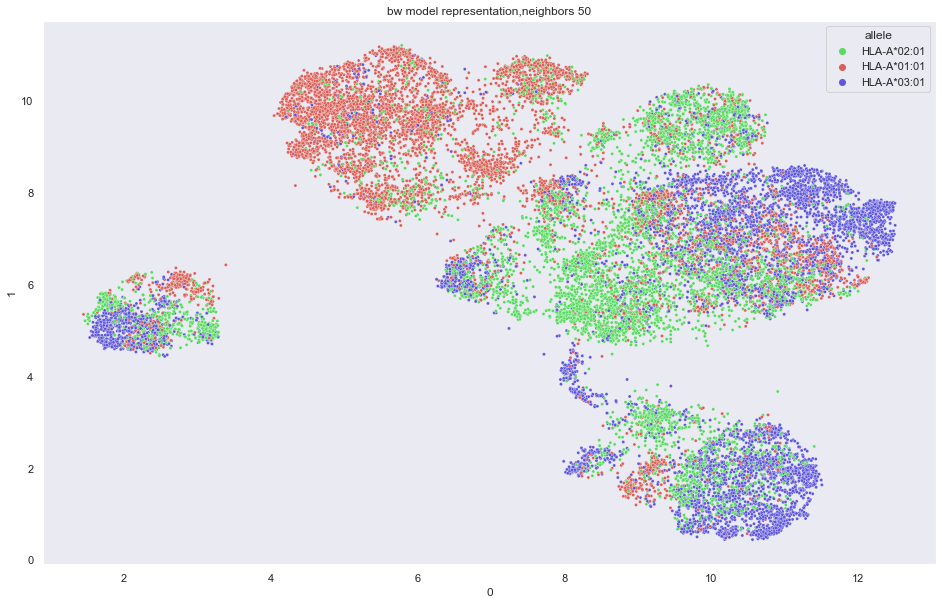

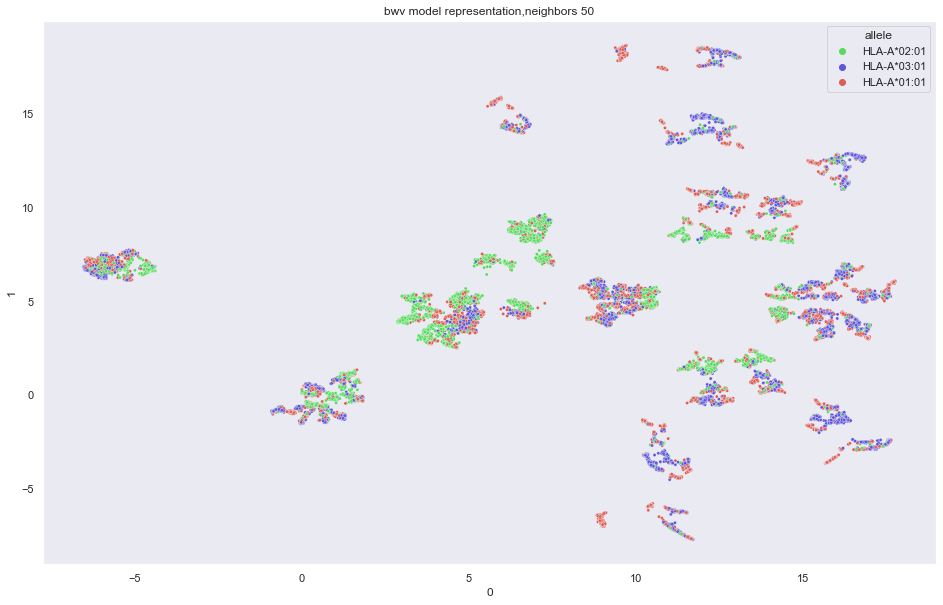

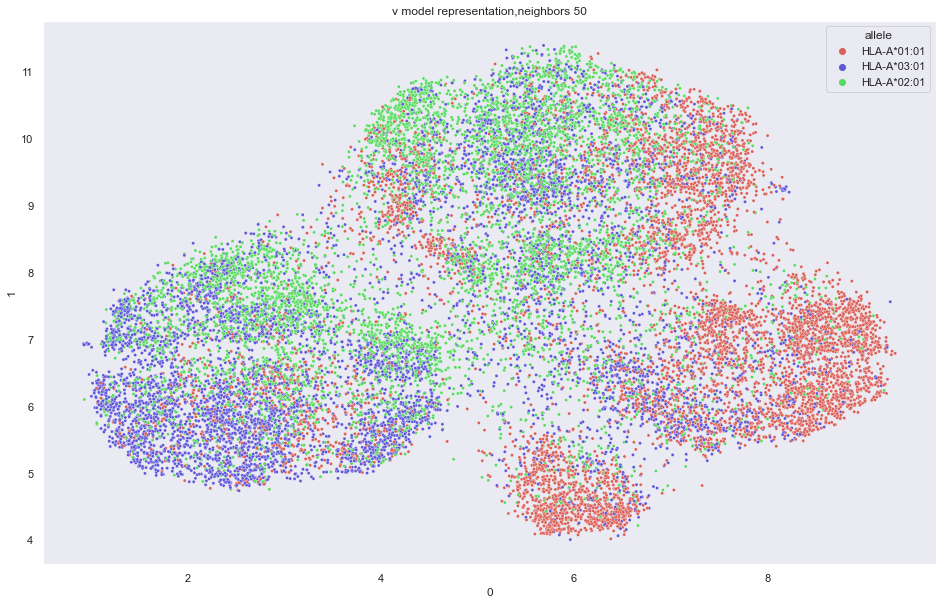

In [150]:
%%time
n = 50

train_embedding_bw = None
train_embedding_bwv = None
train_embedding_v= None

test_embedding_bw = None
test_embedding_bwv = None
test_embedding_v= None

for model, total_model_df in per_model_embedding_result.items():
    print(f"model {model}")
    train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
    test_df = total_model_df[total_model_df['dataset'] == f'Test_db']

    train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
    test_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
    reducer_b, scaler_b = get_reducer(train_data, n_neighbors=n)
    train_embedding = get_umap_embedding(reducer_b, scaler_b, train_data)
    train_embedding['allele'] = train_df['allele']
    train_embedding['dataset'] = train_df['dataset']
    train_embedding['length'] = train_embedding.index.str.len()
    test_embedding = get_umap_embedding(reducer_b, scaler_b, test_data)
    test_embedding['allele'] = test_df['allele']
    test_embedding['dataset'] = test_df['dataset']
    test_embedding['length'] = test_embedding.index.str.len()
    if model == "bw":
        train_embedding_bw = train_embedding
        test_embedding_bw = test_embedding
    elif model == 'bwv':
        train_embedding_bwv = train_embedding
        test_embedding_bwv = test_embedding
    elif model == 'v':
        train_embedding_v = train_embedding
        test_embedding_v = test_embedding

    fig = make_scatter_plot_sns(train_embedding, title=f"{model} model representation,neighbors {n}", hue_column='allele')

## Analyze motifs

In [145]:
def make_logo(df, length=9):
    filtered = df[df['length'] == length]
    matrix = logomaker.alignment_to_matrix(filtered['peptide'].values)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    counts = df['allele'].value_counts()
    # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
    ww_logo.ax.set_title(f" Allele counts: {counts}")

def select_rectangle(df, x1, x2, y1, y2):
    filtered_df = df[(df[0] > x1) & (df[0] < x2) & (df[1] > y1) & (df[1] < y2)]
    filtered_df['peptide'] = filtered_df.index
    return filtered_df


In [146]:
counts = train_embedding['allele'].value_counts()
counts

HLA-A*02:01    6666
HLA-A*03:01    6618
HLA-A*01:01    6589
Name: allele, dtype: int64

In [147]:
train_embedding = train_embedding_v
filtered_1 = select_rectangle(train_embedding, 0, 4, 0, 8)
filtered_2 = select_rectangle(train_embedding, 5, 7, 0, 5.2)

filtered_3 = select_rectangle(train_embedding, 6.1, 10, 5, 7.5)
filtered_4 = select_rectangle(train_embedding, 3, 8, 8, 15)

# #
# #
filtered_5 = select_rectangle(train_embedding, 4, 6, 5.5, 7.5)
filtered_6 = select_rectangle(train_embedding, 3.2, 4, 0, 7.5)
# #

C:\Users\denkl\AppData\Local\Temp/ipykernel_25764/2837600045.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['peptide'] = filtered_df.index


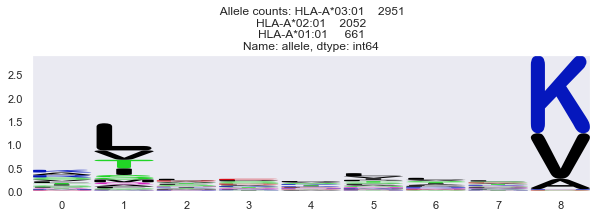

In [148]:
make_logo(filtered_1) # ... 

## Save to file

In [154]:
def save_umap(embedding, model, type_of_data="train"):
    print(f"model {model}")
    TARGET_PATH_TO_FILES =  name_to_model_root[model] + model
    assert train_embedding['allele'].isnull().sum() == 0
    embedding.to_csv("{}/{}_umap.csv".format(TARGET_PATH_TO_FILES, type_of_data),sep=";", index=True)
    


In [155]:
save_umap(train_embedding_bw, mixed_model_bw, type_of_data="train")
save_umap(test_embedding_bw, mixed_model_bw, type_of_data="test")

save_umap(train_embedding_bwv, mixed_model_bwv, type_of_data="train")
save_umap(test_embedding_bwv, mixed_model_bwv, type_of_data="test")

save_umap(train_embedding_v, mixed_model_v, type_of_data="train")
save_umap(test_embedding_v, mixed_model_v, type_of_data="test")



model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0


## Per length picture

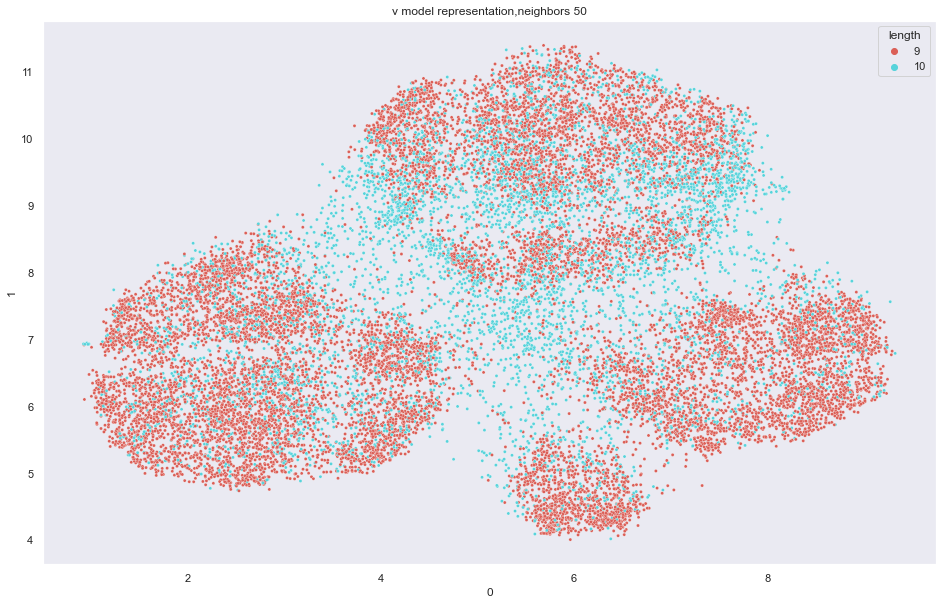

In [157]:
fig = make_scatter_plot_sns(train_embedding_v, title=f"{model} model representation,neighbors {n}", hue_column='length')

# Some old alanysis just for history

# Test clustering approaches
## Run PCA  first (as it's suggested by K-Means)
### Get pca objects

In [36]:
per_name_representation_train['v']['db'].head()

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,allele,label
PVSMTYLYNK,-0.767756,-1.088749,-1.088269,-1.136451,-1.110482,-1.126951,-0.866452,-0.985360,-0.735749,-0.874844,...,-1.145076,-1.230186,-1.147024,-0.874245,-1.095748,-1.457219,-1.120143,-1.239554,HLA-A*03:01,1
NYDLALKYF,-1.133209,-0.807913,-0.938645,-0.989824,-1.055381,-0.980324,-1.221345,-1.072828,-1.225003,-1.003204,...,-0.936420,-0.907656,-1.070104,-1.219688,-1.100022,-1.130287,-1.023211,-1.052718,HLA-A*01:01,0
TLKSFTVEK,-1.045980,-1.164910,-1.164430,-1.309880,-1.180526,-1.442628,-1.052648,-1.166878,-1.043307,-1.047711,...,-1.336272,-1.034953,-1.058531,-1.171488,-1.067980,-1.081329,-1.393245,-1.207510,HLA-A*03:01,1
AIFTDASTV,-1.062561,-0.941709,-0.941229,-0.655181,-0.822113,-0.645681,-1.069229,-1.062961,-1.006282,-0.945006,...,-0.834980,-0.810637,-0.835843,-0.821074,-0.946041,-1.074098,-0.576180,-0.962399,HLA-A*02:01,2
KLEYLAPSY,-1.049917,-0.929065,-0.928585,-0.919620,-0.980604,-1.052369,-0.925646,-1.050318,-1.060243,-0.932363,...,-1.184716,-0.893841,-0.919782,-1.054928,-1.011185,-1.143730,-1.156217,-1.098082,HLA-A*01:01,0


In [37]:
import sklearn
import seaborn as sns
from sklearn.decomposition import PCA
from collections import defaultdict

def get_pca(df_concat, n_components=2, target_cols=["allele","dataset", "label"],  whiten=True):
    X = df_concat.drop(columns=target_cols, errors='ignore').values
    pca = PCA(n_components=n_components, whiten=whiten)
    print(f"Shape {X.shape}")
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

def get_pca_embedding(pca, data, target_cols=["allele","dataset", "label"]):
    X = data.drop(columns=target_cols, errors='ignore').values
    print(f"Shape of X {X.shape}")
    pca_result = pca.transform(X)
    df = pd.DataFrame(pca_result, index=data.index)
    return df




In [38]:
pca_bw = get_pca(pd.concat([per_name_representation_train['bw']['db']]), n_components=15)
pca_bwv = get_pca(pd.concat([per_name_representation_train['bwv']['db']]), n_components=15)
pca_v = get_pca(pd.concat([per_name_representation_train['v']['db']]), n_components=15)

Shape (20234, 1518)
Explained variation per principal component: [0.35394269 0.23587922 0.10104998 0.06258665 0.03244827 0.02813503
 0.02620156 0.02189285 0.01944591 0.01761573 0.012354   0.01153913
 0.01045792 0.00939453 0.00877473]
Shape (20234, 862)
Explained variation per principal component: [0.16391172 0.16114598 0.12877053 0.09399624 0.07988388 0.05734928
 0.05676028 0.04665017 0.03450371 0.03296763 0.03177579 0.02852508
 0.01591615 0.01296891 0.01113115]
Shape (20234, 2000)
Explained variation per principal component: [0.22852142 0.09858035 0.09364597 0.07301351 0.05111895 0.04725978
 0.04057294 0.0359668  0.03514807 0.029157   0.0243041  0.02106872
 0.02026886 0.01762114 0.01541918]


<AxesSubplot:>

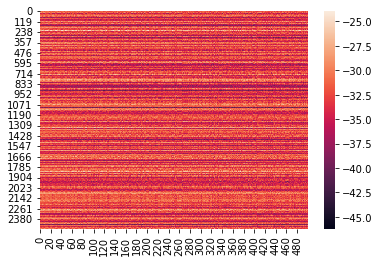

In [44]:
sns.heatmap(per_name_representation_test['bw']['db'].drop(columns=["allele"]).values)

<AxesSubplot:>

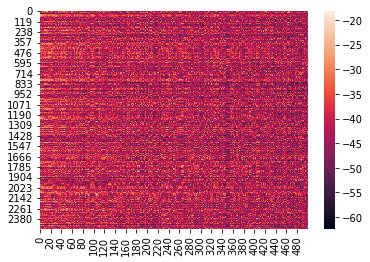

In [45]:
sns.heatmap(per_name_representation_test['bwv']['db'].drop(columns=["allele"]).values)

<AxesSubplot:>

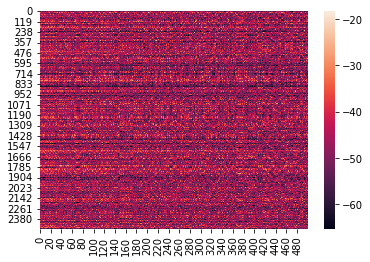

In [46]:
sns.heatmap(per_name_representation_test['v']['db'].drop(columns=["allele"]).values)

In [39]:
df = per_name_representation_train['bwv']['db'].drop(columns=["allele"]).copy().T

In [40]:
def collect_embeddings_with_pca_or_without(train_data, test_data, pca):
    columns_to_drop = ["dataset", "allele", "label"]
    if pca:
        train_embedding = get_pca_embedding(pca, train_data)
        test_embedding = get_pca_embedding(pca, test_data)
    else:
        train_embedding = train_data.drop(columns=columns_to_drop, errors='ignore')
        test_embedding = test_data.drop(columns=columns_to_drop, errors='ignore')
    if "allele" in train_data.columns:
        alleles_train = train_data['allele'].values
        alleles_test = test_data['allele'].values


    train_df = pd.DataFrame(train_embedding, index=train_data.index)
    train_df['dataset'] = 'Train'
    train_df['allele'] = alleles_train
    test_df = pd.DataFrame(test_embedding, index=test_data.index)
    test_df['dataset'] = 'Test'
    test_df['allele'] = alleles_test

    total_embedding = pd.concat([train_df, test_df])
    return total_embedding

In [41]:
def get_embedding_for_selected_models_using_pca(pca_bw, pca_bwv, pca_v):
    per_model_embedding_result= dict()
    for model_key in ['bw', 'bwv', 'v']:
        if model_key == 'bw':
            model_name = 'bw'
            pca = pca_bw
        elif model_key == 'bwv':
            model_name = 'bwv'
            pca = pca_bwv
        else:
            model_name = 'v'
            pca = pca_v

        train_repr = per_name_representation_train[model_name]['db'].copy()
        test_repr = per_name_representation_test[model_name]['db'].copy()
        total_embedding_db = collect_embeddings_with_pca_or_without(train_repr, test_repr, pca)
        total_embedding_db['dataset'] = total_embedding_db['dataset'] + '_db'

        total_embedding = pd.concat([total_embedding_db])
        per_model_embedding_result[model_key] = total_embedding
    return per_model_embedding_result


In [42]:
%%time
per_model_embedding_result_without_pca = get_embedding_for_selected_models_using_pca(None, None, None)
per_model_embedding_result = get_embedding_for_selected_models_using_pca(pca_bw, pca_bwv, pca_v)
# per_model_embedding_result_w = get_embedding_for_selected_models_using_pca(pca_b_w, pca_i_w)

Shape of X (20234, 1518)
Shape of X (5328, 1518)
Shape of X (20234, 862)
Shape of X (5328, 862)
Shape of X (20234, 2000)
Shape of X (5328, 2000)
Wall time: 8.75 s


In [47]:
per_model_embedding_result_without_pca['bw'].head()

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,dataset,allele
ILSVSSFLFV,-0.364700,-0.381235,-0.367528,-0.378544,-0.371532,-0.351285,-0.366476,-0.361727,-0.388066,-0.349998,...,-0.438859,-0.464207,-0.405298,-0.479072,-0.384629,-0.439330,-0.419626,-0.406906,Train_db,HLA-A*02:01
YLGPRVCWL,-0.374002,-0.369963,-0.375464,-0.363823,-0.388018,-0.381692,-0.384524,-0.392517,-0.383978,-0.387589,...,-0.410033,-0.444902,-0.463343,-0.438130,-0.434872,-0.426301,-0.446673,-0.479272,Train_db,HLA-A*02:01
QTCLELERY,-0.389160,-0.398793,-0.392251,-0.411826,-0.405771,-0.385542,-0.391964,-0.351665,-0.415405,-0.394036,...,-0.476823,-0.481462,-0.469280,-0.492324,-0.443472,-0.422930,-0.480558,-0.461514,Train_db,HLA-A*01:01
YTIERIFNAK,-0.355430,-0.371965,-0.358258,-0.369274,-0.369446,-0.372350,-0.354239,-0.358270,-0.385980,-0.378247,...,-0.461023,-0.447076,-0.439204,-0.427925,-0.459893,-0.415830,-0.422495,-0.515466,Train_db,HLA-A*03:01
TAYGPNGMNK,-0.481032,-0.470816,-0.471870,-0.453353,-0.481343,-0.498497,-0.516707,-0.511324,-0.471128,-0.490691,...,-0.486136,-0.465521,-0.448926,-0.452600,-0.524882,-0.466095,-0.473271,-0.494837,Train_db,HLA-A*03:01


In [48]:
per_model_embedding_result_without_pca['bwv'].head()

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,dataset,allele
ILSVSSFLFV,-0.375824,-0.458435,-0.438305,-0.462972,-0.399262,-0.375359,-0.307893,-0.396597,-0.424391,-0.526497,...,-0.690939,-0.748143,-0.797170,-0.690649,-0.696509,-0.549402,-0.656650,-0.580109,Train_db,HLA-A*02:01
YLGPRVCWL,-0.375384,-0.375884,-0.318415,-0.453251,-0.469359,-0.384728,-0.410935,-0.332883,-0.527944,-0.381633,...,-0.512078,-0.637890,-0.651993,-0.668445,-0.778125,-0.581005,-0.543768,-0.582657,Train_db,HLA-A*02:01
QTCLELERY,-0.490758,-0.573580,-0.576579,-0.549482,-0.576087,-0.584300,-0.417656,-0.526961,-0.325174,-0.647071,...,-0.732136,-0.849313,-0.788534,-0.601646,-0.662889,-0.646481,-0.783966,-0.643668,Train_db,HLA-A*01:01
YTIERIFNAK,-0.470495,-0.553105,-0.628358,-0.386680,-0.564470,-0.555947,-0.510853,-0.503916,-0.348079,-0.556329,...,-0.557415,-0.681102,-0.640245,-0.638204,-0.625053,-0.591918,-0.765382,-0.705399,Train_db,HLA-A*03:01
TAYGPNGMNK,-0.507488,-0.507989,-0.432012,-0.592135,-0.530785,-0.420424,-0.549782,-0.379522,-0.602320,-0.366064,...,-0.568634,-0.643238,-0.670440,-0.651408,-0.634305,-0.561511,-0.578042,-0.655989,Train_db,HLA-A*03:01


In [49]:
per_name_representation_train['bw']['db'].head()

,0,1,2,3,4,5,6,7,8,9,...,1991,1992,1993,1994,1995,1996,1997,1998,1999,allele
ILSVSSFLFV,-0.364700,-0.381235,-0.367528,-0.378544,-0.371532,-0.351285,-0.366476,-0.361727,-0.388066,-0.349998,...,-0.413016,-0.438859,-0.464207,-0.405298,-0.479072,-0.384629,-0.439330,-0.419626,-0.406906,HLA-A*02:01
YLGPRVCWL,-0.374002,-0.369963,-0.375464,-0.363823,-0.388018,-0.381692,-0.384524,-0.392517,-0.383978,-0.387589,...,-0.408443,-0.410033,-0.444902,-0.463343,-0.438130,-0.434872,-0.426301,-0.446673,-0.479272,HLA-A*02:01
QTCLELERY,-0.389160,-0.398793,-0.392251,-0.411826,-0.405771,-0.385542,-0.391964,-0.351665,-0.415405,-0.394036,...,-0.445261,-0.476823,-0.481462,-0.469280,-0.492324,-0.443472,-0.422930,-0.480558,-0.461514,HLA-A*01:01
YTIERIFNAK,-0.355430,-0.371965,-0.358258,-0.369274,-0.369446,-0.372350,-0.354239,-0.358270,-0.385980,-0.378247,...,-0.426974,-0.461023,-0.447076,-0.439204,-0.427925,-0.459893,-0.415830,-0.422495,-0.515466,HLA-A*03:01
TAYGPNGMNK,-0.481032,-0.470816,-0.471870,-0.453353,-0.481343,-0.498497,-0.516707,-0.511324,-0.471128,-0.490691,...,-0.458310,-0.486136,-0.465521,-0.448926,-0.452600,-0.524882,-0.466095,-0.473271,-0.494837,HLA-A*03:01


In [43]:
from collections import defaultdict
from sklearn.cluster import KMeans

def cluster_total_embedding(total_embedding_dfs, per_model_predictor):
    total_clustering_result = defaultdict(list)
    for m_key in total_embedding_dfs.keys():
        # print(f"model_key {m_key}")
        total_model_df =  total_embedding_dfs[m_key].copy()
        representation_df = total_model_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
        representation_df['label'] = per_model_predictor[m_key].predict(representation_df.values)
        representation_df['dataset'] = total_model_df['dataset']

        total_clustering_result[m_key] = representation_df

    return total_clustering_result

In [44]:
def clustering_experiment(total_embedding_df, cluster_counts):
    """
        Train will be used for training
        All other datasets will be fitted
    """

    per_cluster_count_result = dict()
    for cluster_count in cluster_counts:
        print(f"cluster_count {cluster_count}")
        # bw
        kmeans_bw = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['bw'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore').values
        kmeans_bw.fit(train_data)
        # bwv
        kmeans_bwv = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['bwv'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore').values
        kmeans_bwv.fit(train_data)

        # bwv
        kmeans_v = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['v'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide","allele"],  errors='ignore').values
        kmeans_v.fit(train_data)
        # # immmune model
        # total_model_df = total_embedding_df['mi'].copy()
        # kmeans_i = KMeans(n_clusters= cluster_count)
        # #extract train_data ensure no peptide columns
        # train_df =total_model_df[total_model_df['dataset'] == f'Train_di']
        # train_data = train_df.drop(columns=["dataset", "peptide"],  errors='ignore').values
        # kmeans_i.fit(train_data)

        total_clustering_result = cluster_total_embedding(total_embedding_df, {"bw":kmeans_bw , "bwv":kmeans_bwv, "v": kmeans_v})
        per_cluster_count_result[cluster_count] = total_clustering_result
    return per_cluster_count_result

In [45]:
cluster_counts = [2 , 4,  5]
per_cluster_count_result_pca = clustering_experiment(per_model_embedding_result, cluster_counts=cluster_counts)
per_cluster_count_result_repr = clustering_experiment(per_model_embedding_result_without_pca, cluster_counts=cluster_counts)

cluster_count 2
cluster_count 4
cluster_count 5
cluster_count 2
cluster_count 4
cluster_count 5


## Plot PCA plots

3    3794
0    3145
1    2168
2    1940
4     686
Name: label, dtype: int64


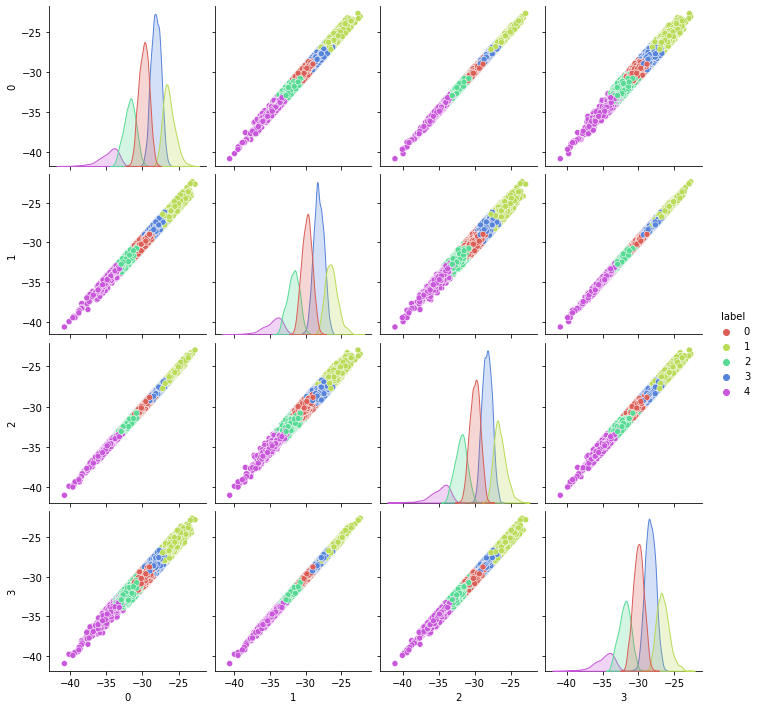

In [108]:
clusters_count = 5
sample_df = per_cluster_count_result_repr[clusters_count]['bw']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))


4    3045
0    2433
2    2372
1    2096
3    1787
Name: label, dtype: int64


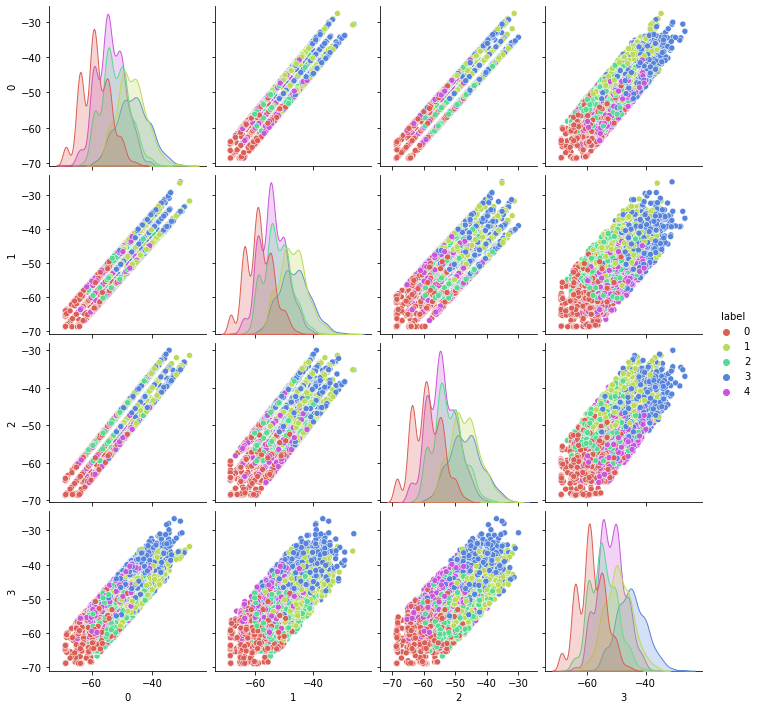

In [109]:
clusters_count = 5
sample_df = per_cluster_count_result_repr[clusters_count]['v']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

2    3511
0    3262
3    2737
1    1207
4    1016
Name: label, dtype: int64


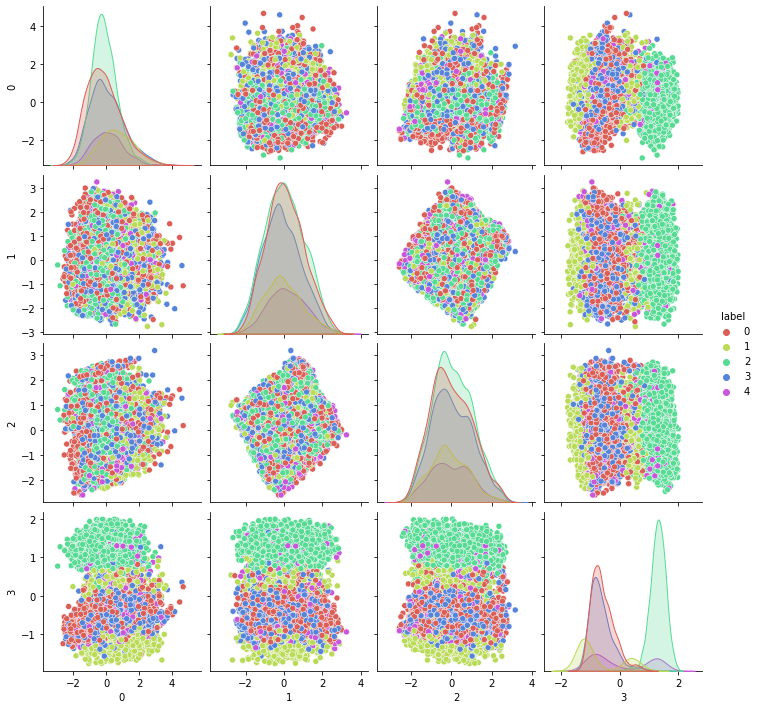

In [57]:
clusters_count = 5
sample_df = per_cluster_count_result_pca[clusters_count]['bw']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

1    4276
4    3622
0    3598
3    3176
2    2798
Name: label, dtype: int64


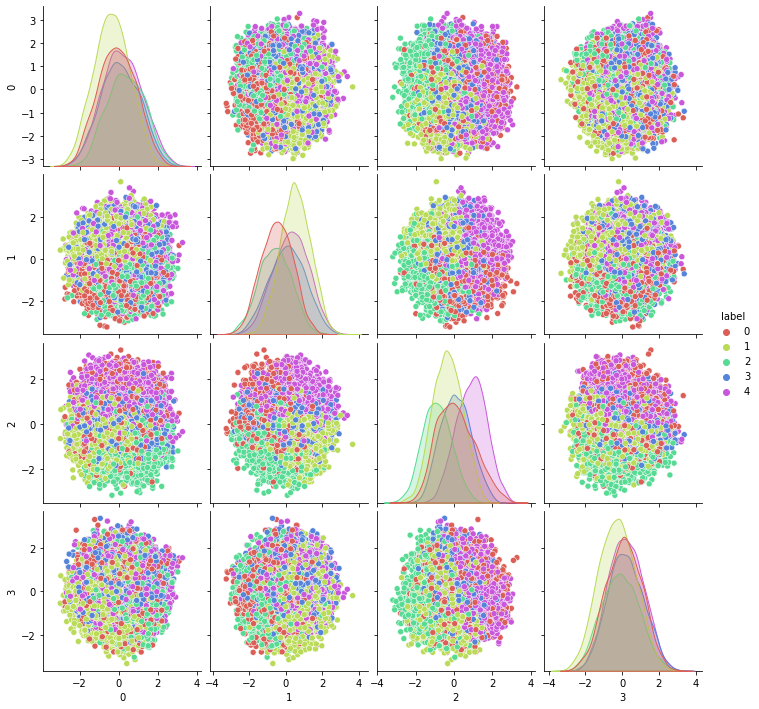

In [68]:
clusters_count = 5
sample_df = per_cluster_count_result_pca[clusters_count]['v']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

1    4152
3    2817
4    2705
2    1567
0     492
Name: label, dtype: int64


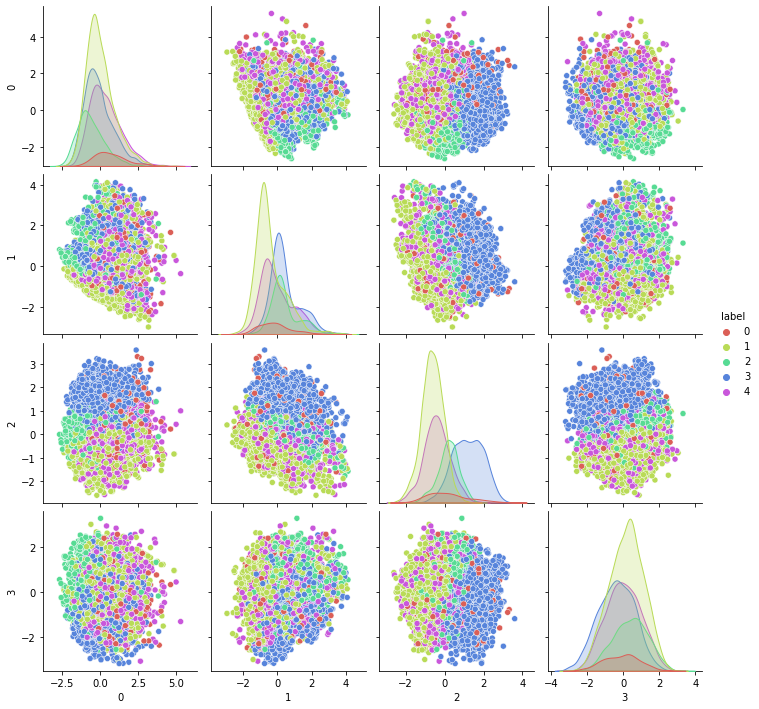

In [86]:
clusters_count = 5
sample_df = per_cluster_count_result_pca[clusters_count]['bwv']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

In [96]:
df

,0,1,2,3,label
0,0.999295,0.387324,0.678455,-0.490383,3
1,0.108097,0.021062,0.669517,1.430231,3
2,-0.489513,0.130982,2.365413,-0.590073,0
3,0.476359,-0.651274,1.616374,-0.909632,0
4,0.215536,1.019187,-1.049684,0.503872,4
...,...,...,...,...,...
11728,1.826773,0.694532,-0.540280,0.434760,0
11729,1.655829,0.138762,-0.061199,2.225898,3
11730,-0.679647,-1.219310,-0.063222,1.409131,1
11731,0.944976,-0.191033,0.393523,1.156476,3
